# Forest Cover Type Classification Using Apache Spark and Neural Networks

**Dataset:** UCI Covertype (54 predictors; seven forest cover classes).

**Research question:** How do neural network configurations compare with multinomial logistic regression, and how does Spark partition count affect local aggregation time?

**Execution:** Used `covtype.data` into Jupyter Notebook, run cells in order and retain real outputs. Models are trained using a fixed seed of 42. This notebook runs Spark in local mode, not a multi-machine cluster.

In [2]:
%pip install pyspark pandas numpy matplotlib seaborn scikit-learn pyarrow

In [3]:
import os
import sys
import time
import json
import zipfile
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pyspark.sql import SparkSession
from pyspark.sql import functions as F

from pyspark.ml import Pipeline
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.classification import (
    LogisticRegression,
    MultilayerPerceptronClassifier
)
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

SEED = 42
np.random.seed(SEED)

BASE_DIR = Path.cwd()
DATA_DIR = BASE_DIR / "data"
OUTPUT_DIR = BASE_DIR / "outputs"
MODEL_DIR = BASE_DIR / "models"

for folder in [DATA_DIR, OUTPUT_DIR, MODEL_DIR]:
    folder.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid")

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("Working directory:", BASE_DIR)

Python: 3.13.16
Platform: Linux-6.6.122+-x86_64-with-glibc2.39
Working directory: /content


## 01. Spark Configuration

## Apache Spark is used for distributed-style data processing on a local computer. Record the Spark version, available cores, memory configuration and execution environment for reproducibility.

## **Limitation:** Local execution does not demonstrate multi-machine scalability.

In [5]:
spark = (
    SparkSession.builder
    .appName("ForestCover_Spark_NN")
    .master("local[*]")
    .config("spark.driver.memory", "4g")
    .config("spark.sql.shuffle.partitions", "8")
    .getOrCreate()
)

spark.sparkContext.setLogLevel("WARN")

print("Spark version:", spark.version)
print("Spark master:", spark.sparkContext.master)
print("Parallelism:", spark.sparkContext.defaultParallelism)
print("Spark UI:", spark.sparkContext.uiWebUrl)

Spark version: 4.0.4
Spark master: local[*]
Parallelism: 2
Spark UI: http://6d90367ed99e:4040


## 02. Dataset Loading

Load the headerless Covertype dataset, assign meaningful column names, cast numerical fields and verify its dimensions.

In [11]:
# Cell 06 — Load Forest Cover Dataset using Apache Spark

from pathlib import Path
from pyspark.sql import functions as F

# Dataset location
DATA_PATH = Path("/mnt/data/covtype.data")

# Alternative: automatically find the dataset
if not DATA_PATH.exists():
    candidates = list(Path.cwd().rglob("covtype.data"))

    if candidates:
        DATA_PATH = candidates[0]
    else:
        raise FileNotFoundError(
            "covtype.data not found. Upload the file to your "
            "Jupyter environment and update DATA_PATH."
        )

print("Dataset location:", DATA_PATH)

# Define continuous features
continuous_cols = [
    "Elevation",
    "Aspect",
    "Slope",
    "Horizontal_Distance_To_Hydrology",
    "Vertical_Distance_To_Hydrology",
    "Horizontal_Distance_To_Roadways",
    "Hillshade_9am",
    "Hillshade_Noon",
    "Hillshade_3pm",
    "Horizontal_Distance_To_Fire_Points"
]

# Wilderness features
wilderness_cols = [
    f"Wilderness_Area_{i}"
    for i in range(1, 5)
]

# Soil type features
soil_cols = [
    f"Soil_Type_{i}"
    for i in range(1, 41)
]

# Combine all input features
features = continuous_cols + wilderness_cols + soil_cols

# Target column
target = "Cover_Type"

# Read CSV-format data file using Spark
raw = (
    spark.read
    .option("header", "false")
    .option("inferSchema", "false")
    .csv(str(DATA_PATH))
)

# Validate number of columns
assert len(raw.columns) == 55, (
    f"Expected 55 columns, found {len(raw.columns)}"
)

# Assign column names
df = raw.toDF(*(features + [target]))

# Convert features to numeric
df = df.select(
    *[
        F.col(column).cast("double").alias(column)
        for column in features
    ],
    F.col(target).cast("integer").alias(target)
)

# Validate dataset
row_count = df.count()
column_count = len(df.columns)

print("Dataset loaded successfully!")
print("Total records:", row_count)
print("Total columns:", column_count)
print("Input features:", len(features))

# Display sample
df.show(5, truncate=False)

# Display schema
df.printSchema()

Dataset location: /content/covtype.data
Dataset loaded successfully!
Total records: 581012
Total columns: 55
Input features: 54
+---------+------+-----+--------------------------------+------------------------------+-------------------------------+-------------+--------------+-------------+----------------------------------+-----------------+-----------------+-----------------+-----------------+-----------+-----------+-----------+-----------+-----------+-----------+-----------+-----------+-----------+------------+------------+------------+------------+------------+------------+------------+------------+------------+------------+------------+------------+------------+------------+------------+------------+------------+------------+------------+------------+------------+------------+------------+------------+------------+------------+------------+------------+------------+------------+------------+----------+
|Elevation|Aspect|Slope|Horizontal_Distance_To_Hydrology|Vertical_Distance_To_H

## 03. Data Quality

## Check missing values, duplicate records and invalid target labels. Clean the dataset before modelling, and record the number of rows removed.

In [13]:
total_rows = df.count()
duplicate_count = total_rows - df.dropDuplicates().count()

missing = df.select([
    F.sum(
        F.when(F.col(c).isNull() | F.isnan(F.col(c)), 1)
        .otherwise(0)
    ).alias(c)
    for c in features
]).toPandas()

display(missing.T.rename(columns={0: "Missing_Count"}))

start = time.perf_counter()

clean_df = (
    df.dropna()
    .dropDuplicates()
    .filter(F.col("Cover_Type").between(1, 7))
    .withColumn(
        "label",
        (F.col("Cover_Type") - 1).cast("double")
    )
    .cache()
)

clean_count = clean_df.count()
cleaning_seconds = time.perf_counter() - start

print("Original rows:", total_rows)
print("Duplicates:", duplicate_count)
print("Clean rows:", clean_count)
print("Removed rows:", total_rows - clean_count)
print("Cleaning time:", round(cleaning_seconds, 3), "s")

,Missing_Count
Elevation,0
Aspect,0
Slope,0
Horizontal_Distance_To_Hydrology,0
Vertical_Distance_To_Hydrology,0
Horizontal_Distance_To_Roadways,0
Hillshade_9am,0
Hillshade_Noon,0
Hillshade_3pm,0
Horizontal_Distance_To_Fire_Points,0


Original rows: 581012
Duplicates: 0
Clean rows: 581012
Removed rows: 0
Cleaning time: 49.36 s


## 04. Exploratory Data Analysis

## Investigate class balance and numerical feature distributions. Class imbalance is important because overall accuracy may conceal weak performance on minority forest cover types.

,Cover_Type,count,Percentage
0,1,211840,36.460521
1,2,283301,48.759922
2,3,35754,6.153746
3,4,2747,0.472796
4,5,9493,1.633873
5,6,17367,2.989095
6,7,20510,3.530048


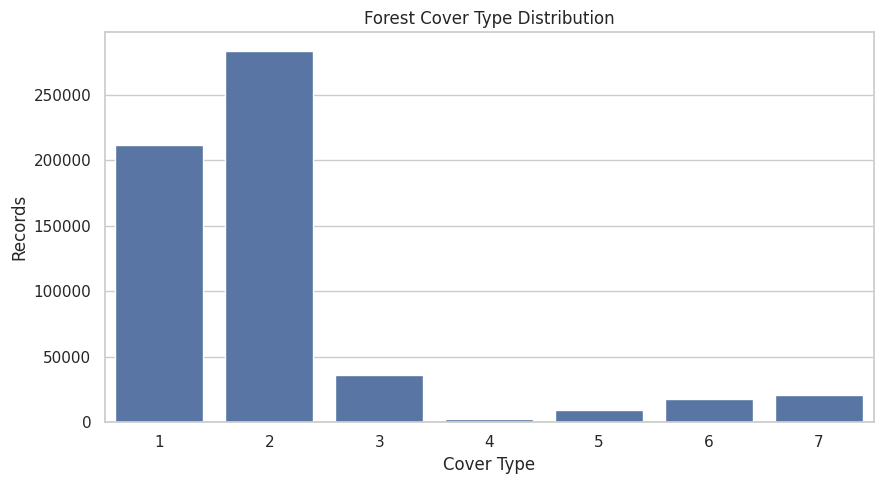

In [14]:
class_counts = (
    clean_df.groupBy("Cover_Type")
    .count()
    .orderBy("Cover_Type")
    .toPandas()
)

class_counts["Percentage"] = (
    class_counts["count"] / clean_count * 100
)

display(class_counts)

plt.figure(figsize=(9, 5))
sns.barplot(
    data=class_counts,
    x="Cover_Type",
    y="count"
)
plt.title("Forest Cover Type Distribution")
plt.xlabel("Cover Type")
plt.ylabel("Records")
plt.tight_layout()
plt.show()

+-------+-----------------+------------------+------------------+--------------------------------+------------------------------+-------------------------------+------------------+------------------+------------------+----------------------------------+
|summary|Elevation        |Aspect            |Slope             |Horizontal_Distance_To_Hydrology|Vertical_Distance_To_Hydrology|Horizontal_Distance_To_Roadways|Hillshade_9am     |Hillshade_Noon    |Hillshade_3pm     |Horizontal_Distance_To_Fire_Points|
+-------+-----------------+------------------+------------------+--------------------------------+------------------------------+-------------------------------+------------------+------------------+------------------+----------------------------------+
|count  |581012           |581012            |581012            |581012                          |581012                        |581012                         |581012            |581012            |581012            |581012              

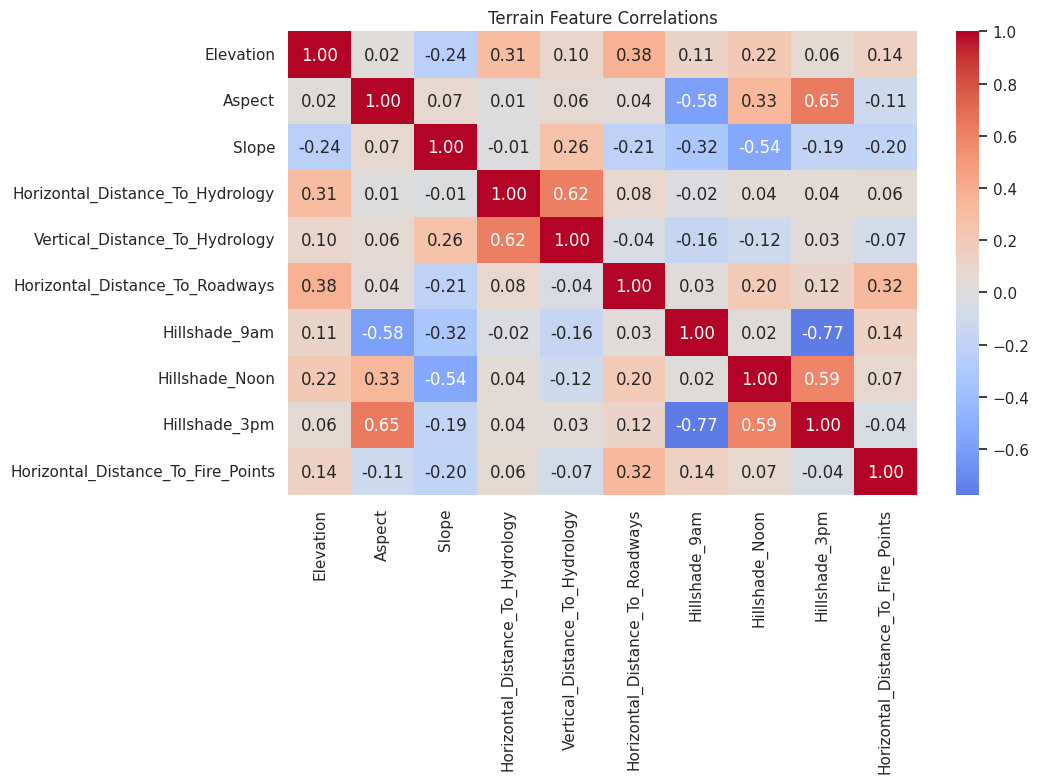

In [15]:
#Feature Statistics and Correlations
clean_df.select(*continuous_cols).summary().show(
    truncate=False
)

sample_pd = (
    clean_df
    .select(*continuous_cols)
    .sample(False, 0.02, seed=SEED)
    .limit(10000)
    .toPandas()
)

plt.figure(figsize=(11, 8))
sns.heatmap(
    sample_pd.corr(),
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".2f"
)
plt.title("Terrain Feature Correlations")
plt.tight_layout()
plt.show()

## 05. Data Preparation

## Split the cleaned dataset into training (70%), validation (15%) and testing (15%) partitions.

## Fit feature scaling only on the training data to prevent information leakage. Use validation results for model selection and reserve the test data for final evaluation.

In [16]:
train_df, val_df, test_df = clean_df.randomSplit(
    [0.70, 0.15, 0.15],
    seed=SEED
)

train_df = train_df.cache()
val_df = val_df.cache()
test_df = test_df.cache()

split_counts = {
    "Training": train_df.count(),
    "Validation": val_df.count(),
    "Testing": test_df.count()
}

display(pd.DataFrame([
    {
        "Split": name,
        "Rows": count,
        "Percentage": round(count / clean_count * 100, 2)
    }
    for name, count in split_counts.items()
]))

assert sum(split_counts.values()) == clean_count

,Split,Rows,Percentage
0,Training,406923,70.04
1,Validation,86973,14.97
2,Testing,87116,14.99


In [17]:
#Spark Feature Pipeline
assembler = VectorAssembler(
    inputCols=features,
    outputCol="raw_features"
)

scaler = StandardScaler(
    inputCol="raw_features",
    outputCol="features",
    withStd=True,
    withMean=False
)

pipeline = Pipeline(stages=[assembler, scaler])

start = time.perf_counter()
pipeline_model = pipeline.fit(train_df)
preprocessing_seconds = time.perf_counter() - start

def prepare(data):
    return (
        pipeline_model.transform(data)
        .select("label", "features")
        .cache()
    )

train_ready = prepare(train_df)
val_ready = prepare(val_df)
test_ready = prepare(test_df)

for dataset in [train_ready, val_ready, test_ready]:
    print("Prepared rows:", dataset.count())

print("Feature count:", len(features))
print("Preprocessing:", round(preprocessing_seconds, 3), "s")

Prepared rows: 406923
Prepared rows: 86973
Prepared rows: 87116
Feature count: 54
Preprocessing: 8.145 s


## 06. Model Development

## Logistic regression provides a baseline for multiclass classification.

## The neural network experiments investigate changes in hidden-layer architecture and optimisation settings. All candidate models are evaluated on the same validation split.

In [18]:
def evaluate_model(predictions):
    metrics = {}

    metric_names = {
        "accuracy": "Accuracy",
        "f1": "Weighted_F1",
        "weightedPrecision": "Weighted_Precision",
        "weightedRecall": "Weighted_Recall"
    }

    for metric, name in metric_names.items():
        evaluator = MulticlassClassificationEvaluator(
            labelCol="label",
            predictionCol="prediction",
            metricName=metric
        )
        metrics[name] = evaluator.evaluate(predictions)

    return metrics


def run_experiment(name, estimator):
    start = time.perf_counter()
    model = estimator.fit(train_ready)
    training_time = time.perf_counter() - start

    start = time.perf_counter()
    predictions = model.transform(val_ready).cache()
    predictions.count()
    prediction_time = time.perf_counter() - start

    result = {
        "Model": name,
        **evaluate_model(predictions),
        "Training_Seconds": round(training_time, 3),
        "Prediction_Seconds": round(prediction_time, 3)
    }

    predictions.unpersist()
    return model, result

In [19]:
#Logistic Regression Baseline
lr = LogisticRegression(
    featuresCol="features",
    labelCol="label",
    family="multinomial",
    maxIter=50,
    regParam=0.01
)

lr_model, lr_result = run_experiment(
    "Logistic Regression",
    lr
)

display(pd.DataFrame([lr_result]))

,Model,Accuracy,Weighted_F1,Weighted_Precision,Weighted_Recall,Training_Seconds,Prediction_Seconds
0,Logistic Regression,0.716257,0.699456,0.706254,0.716257,50.3,1.565


## 07. Iterative Neural Network Experiments

Three multilayer perceptron configurations are compared on the same validation split:

- **NN_1:** 54–32–7, 50 iterations.
- **NN_2:** 54–64–32–7, 100 iterations.
- **NN_3:** 54–128–64–7, 150 iterations.

Hidden-layer dimensions and optimisation settings are changed together, so improvements cannot be attributed to one parameter in isolation.

In [21]:
configs = [
    {
        "name": "NN_1",
        "layers": [54, 32, 7],
        "maxIter": 50,
        "blockSize": 128,
        "stepSize": 0.03
    },
    {
        "name": "NN_2",
        "layers": [54, 64, 32, 7],
        "maxIter": 100,
        "blockSize": 128,
        "stepSize": 0.03
    },
    {
        "name": "NN_3",
        "layers": [54, 128, 64, 7],
        "maxIter": 150,
        "blockSize": 256,
        "stepSize": 0.02
    }
]

nn_models = {}
results = [lr_result]

for config in configs:
    nn = MultilayerPerceptronClassifier(
        featuresCol="features",
        labelCol="label",
        layers=config["layers"],
        maxIter=config["maxIter"],
        blockSize=config["blockSize"],
        stepSize=config["stepSize"],
        seed=SEED
    )

    model, result = run_experiment(
        config["name"],
        nn
    )

    nn_models[config["name"]] = model
    results.append(result)

    print(config["name"], result)

comparison = pd.DataFrame(results)

display(comparison.round(4))

NN_1 {'Model': 'NN_1', 'Accuracy': 0.7079783381049292, 'Weighted_F1': 0.6904291477954471, 'Weighted_Precision': 0.6929843770198103, 'Weighted_Recall': 0.707978338104929, 'Training_Seconds': 61.827, 'Prediction_Seconds': 2.367}
NN_2 {'Model': 'NN_2', 'Accuracy': 0.7387350097156589, 'Weighted_F1': 0.7249374899439325, 'Weighted_Precision': 0.7191733000106264, 'Weighted_Recall': 0.738735009715659, 'Training_Seconds': 411.69, 'Prediction_Seconds': 2.763}
NN_3 {'Model': 'NN_3', 'Accuracy': 0.7462430869350258, 'Weighted_F1': 0.737202473885026, 'Weighted_Precision': 0.7376657247585743, 'Weighted_Recall': 0.7462430869350258, 'Training_Seconds': 1218.087, 'Prediction_Seconds': 1.972}


,Model,Accuracy,Weighted_F1,Weighted_Precision,Weighted_Recall,Training_Seconds,Prediction_Seconds
0,Logistic Regression,0.7163,0.6995,0.7063,0.7163,50.300,1.565
1,NN_1,0.7080,0.6904,0.6930,0.7080,61.827,2.367
2,NN_2,0.7387,0.7249,0.7192,0.7387,411.690,2.763
3,NN_3,0.7462,0.7372,0.7377,0.7462,1218.087,1.972


## 08. Model Comparison

## Compare validation performance with training time. A more complex neural network may improve predictive performance but require additional processing resources.

## Record which changes helped, which did not and whether the improvement justifies the additional computational cos

,Model,Accuracy,Weighted_F1,Weighted_Precision,Weighted_Recall,Training_Seconds,Prediction_Seconds
0,NN_3,0.7462,0.7372,0.7377,0.7462,1218.087,1.972
1,NN_2,0.7387,0.7249,0.7192,0.7387,411.690,2.763
2,Logistic Regression,0.7163,0.6995,0.7063,0.7163,50.300,1.565
3,NN_1,0.7080,0.6904,0.6930,0.7080,61.827,2.367


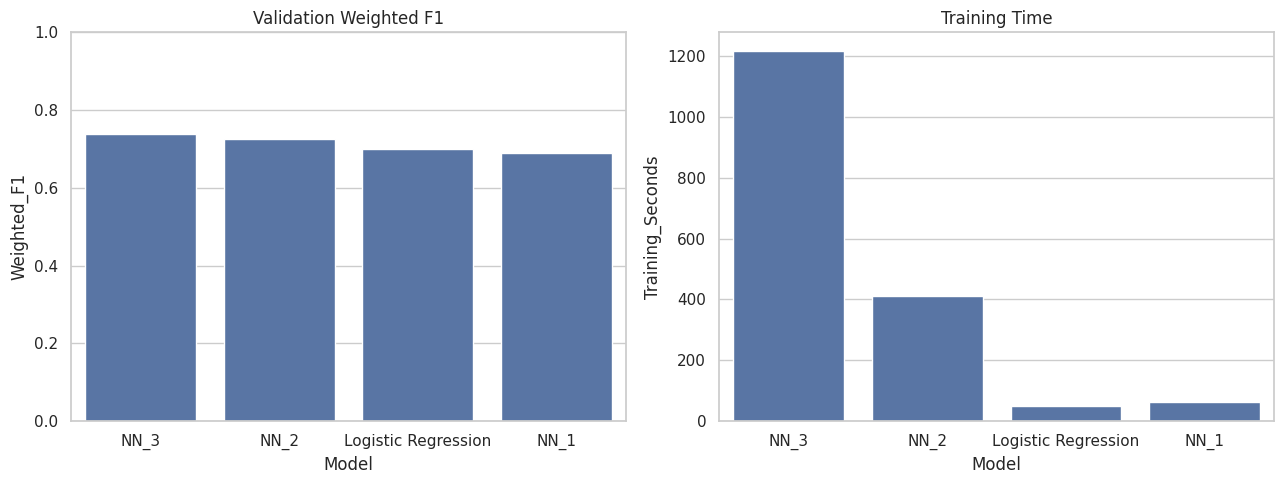

Selected neural network: NN_3


In [23]:
comparison = comparison.sort_values(
    "Weighted_F1",
    ascending=False
).reset_index(drop=True)

display(comparison.round(4))

comparison.to_csv(
    OUTPUT_DIR / "model_comparison.csv",
    index=False
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.barplot(
    data=comparison,
    x="Model",
    y="Weighted_F1",
    ax=axes[0]
)
axes[0].set_title("Validation Weighted F1")
axes[0].set_ylim(0, 1)

sns.barplot(
    data=comparison,
    x="Model",
    y="Training_Seconds",
    ax=axes[1]
)
axes[1].set_title("Training Time")

plt.tight_layout()
plt.show()

nn_only = comparison[
    comparison["Model"].str.startswith("NN_")
]

best_name = nn_only.iloc[0]["Model"]
best_model = nn_models[best_name]

print("Selected neural network:", best_name)

## 09. Final Model Evaluation

## Evaluate the selected neural network once on the held-out test set. Report accuracy, precision, recall, weighted F1 and a confusion matrix.

## Inspect minority-class errors to assess whether the overall performance is representative of all seven cover types.

In [24]:
test_predictions = best_model.transform(test_ready).cache()
test_predictions.count()

test_metrics = evaluate_model(test_predictions)

display(pd.DataFrame([{
    "Model": best_name,
    **test_metrics
}]))

pd.DataFrame([test_metrics]).to_csv(
    OUTPUT_DIR / "test_metrics.csv",
    index=False
)

,Model,Accuracy,Weighted_F1,Weighted_Precision,Weighted_Recall
0,NN_3,0.744697,0.735925,0.737643,0.744697


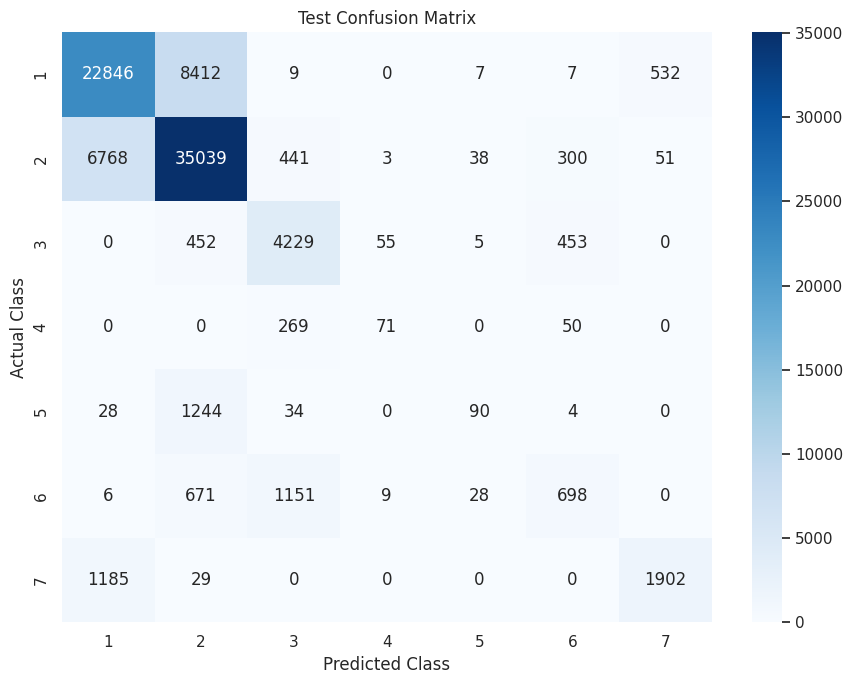

              precision    recall  f1-score   support

Cover Type 1       0.74      0.72      0.73   31813.0
Cover Type 2       0.76      0.82      0.79   42640.0
Cover Type 3       0.69      0.81      0.75    5194.0
Cover Type 4       0.51      0.18      0.27     390.0
Cover Type 5       0.54      0.06      0.11    1400.0
Cover Type 6       0.46      0.27      0.34    2563.0
Cover Type 7       0.77      0.61      0.68    3116.0

    accuracy                           0.74   87116.0
   macro avg       0.64      0.50      0.52   87116.0
weighted avg       0.74      0.74      0.74   87116.0



,Cover_Type,Recall
0,1,0.718134
1,2,0.821740
2,3,0.814209
3,4,0.182051
4,5,0.064286
5,6,0.272337
6,7,0.610398


In [25]:
#Confusion Matrix and Classification Report
from sklearn.metrics import classification_report

counts = (
    test_predictions
    .groupBy("label", "prediction")
    .count()
    .toPandas()
)

cm = np.zeros((7, 7), dtype=int)

for row in counts.itertuples(index=False):
    cm[int(row.label), int(row.prediction)] = int(row.count)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=range(1, 8),
    yticklabels=range(1, 8)
)

plt.title("Test Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "confusion_matrix.png",
    dpi=300
)
plt.show()

actual = np.repeat(np.arange(7), 7)
predicted = np.tile(np.arange(7), 7)

print(classification_report(
    actual,
    predicted,
    sample_weight=cm.ravel(),
    labels=np.arange(7),
    target_names=[f"Cover Type {i}" for i in range(1, 8)],
    zero_division=0
))

per_class_recall = np.divide(
    cm.diagonal(),
    cm.sum(axis=1),
    out=np.zeros(7, dtype=float),
    where=cm.sum(axis=1) != 0
)

display(pd.DataFrame({
    "Cover_Type": range(1, 8),
    "Recall": per_class_recall
}))

## 10. Big Data Processing Benchmark

## Compare Spark execution time under different partition counts using the same aggregation operation.

## This investigates local parallel processing behaviour. Execution times can vary because of caching, scheduling overhead and hardware conditions.

,Partitions,Mean_Seconds,Std_Seconds
0,2,2.925,2.991
1,4,0.876,0.009
2,8,1.538,0.253


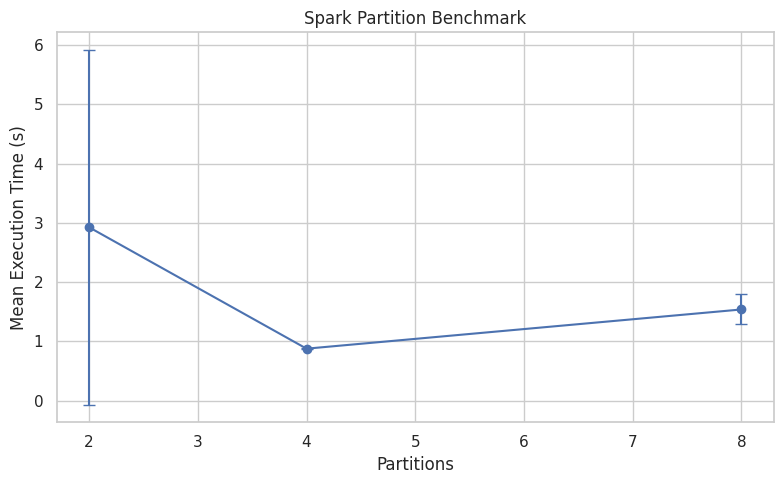

In [26]:
benchmark_results = []

for partitions in [2, 4, 8]:

    times = []

    for trial in range(3):
        benchmark_df = clean_df.repartition(partitions)

        start = time.perf_counter()

        benchmark_df.groupBy("Cover_Type").agg(
            F.count("*").alias("Records"),
            F.avg("Elevation").alias("Average_Elevation")
        ).collect()

        times.append(time.perf_counter() - start)

    benchmark_results.append({
        "Partitions": partitions,
        "Mean_Seconds": np.mean(times),
        "Std_Seconds": np.std(times, ddof=1)
    })

benchmark = pd.DataFrame(benchmark_results)
display(benchmark.round(3))

plt.figure(figsize=(8, 5))
plt.errorbar(
    benchmark["Partitions"],
    benchmark["Mean_Seconds"],
    yerr=benchmark["Std_Seconds"],
    marker="o",
    capsize=4
)

plt.title("Spark Partition Benchmark")
plt.xlabel("Partitions")
plt.ylabel("Mean Execution Time (s)")
plt.tight_layout()
plt.show()

benchmark.to_csv(
    OUTPUT_DIR / "spark_benchmark.csv",
    index=False
)

## 11. Model Persistence

## Save the selected neural network and fitted feature transformation pipeline. Verify that the saved model produces consistent predictions after reloading.

In [27]:
from pyspark.ml import PipelineModel
from pyspark.ml.classification import (
    MultilayerPerceptronClassificationModel
)

nn_path = str(MODEL_DIR / "best_nn")
pipeline_path = str(MODEL_DIR / "preprocessing")

best_model.write().overwrite().save(nn_path)
pipeline_model.write().overwrite().save(pipeline_path)

loaded_model = MultilayerPerceptronClassificationModel.load(
    nn_path
)

loaded_pipeline = PipelineModel.load(pipeline_path)

reloaded_predictions = loaded_model.transform(test_ready)
reloaded_metrics = evaluate_model(reloaded_predictions)

assert abs(
    reloaded_metrics["Accuracy"] - test_metrics["Accuracy"]
) < 1e-10

print("Saved model verified successfully.")

Saved model verified successfully.


## 12. Critical Evaluation — Interpret Your Results

Use your executed output to discuss the change in accuracy and weighted F1 relative to training cost. The selected model improved weighted validation F1, but class imbalance made minority-class performance weak. Contrast class-specific recall with overall accuracy.

Explain that partition timing was measured only in local Spark, and that no separate scaled-versus-unscaled or CSV-versus-Parquet comparison was performed. Discuss the limitations of the single random split and changing multiple hyperparameters together. Add your own literature-linked interpretation in the report.

In [ ]:
summary = {
    "dataset": str(DATA_PATH),
    "spark_version": spark.version,
    "spark_master": spark.sparkContext.master,
    "random_seed": SEED,
    "rows_after_cleaning": clean_count,
    "feature_count": len(features),
    "split_counts": split_counts,
    "selected_neural_network": best_name,
    "test_metrics": test_metrics,
    "preprocessing_seconds": preprocessing_seconds
}

with open(
    OUTPUT_DIR / "experiment_summary.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(summary, file, indent=2)

print(json.dumps(summary, indent=2))

## 13. Conclusion

## Summarise the experimentally observed relationship between neural network complexity, predictive performance and Spark processing time.

## Identify the principal limitations and future improvements, such as stratified evaluation, additional feature engineering, cross-validation and genuine multi-node benchmarking.

In [30]:
test_predictions.unpersist()

for dataset in [
    train_ready, val_ready, test_ready,
    train_df, val_df, test_df, clean_df
]:
    dataset.unpersist()

print("Experiment outputs:", OUTPUT_DIR.resolve())
print("Saved models:", MODEL_DIR.resolve())

spark.stop()
print("Spark session stopped.")

Experiment outputs: /content/outputs
Saved models: /content/models
Spark session stopped.
